In [1]:
# Import-fix / M4
import sys, os
from pathlib import Path

WORK    = Path(r"D:\Projects\MediLens")
TRAINER = WORK / "EasyOCR" / "trainer"
config_path = TRAINER / "config_files" / "medical_prescription.yaml"
RESULTS = WORK / "results"; RESULTS.mkdir(exist_ok=True)
MODELS  = WORK / "models";  MODELS.mkdir(exist_ok=True)

# drop any wrongly-resolved modules, then put the trainer first on the path
for k in ("utils", "model", "dataset", "test", "train"):
    sys.modules.pop(k, None)
sys.path.insert(0, str(TRAINER))
os.chdir(TRAINER)

import utils
print(utils.__file__)                          # must end with ...\trainer\utils.py
from utils import AttrDict, CTCLabelConverter

D:\Projects\MediLens\EasyOCR\trainer\utils.py


In [2]:
# Set-up and helpers/ M8
import gc, numpy as np, pandas as pd, torch, yaml, easyocr
import torch.nn.functional as F
from PIL import Image
from nltk.metrics.distance import edit_distance
from utils import AttrDict, CTCLabelConverter
from model import Model

device = torch.device("cuda")
base = TRAINER / "all_data"

with open(config_path, encoding="utf-8") as fh:
    opt = AttrDict(yaml.safe_load(fh))
opt.character = opt.number + opt.symbol + opt.lang_char
ft_converter = CTCLabelConverter(opt.character)
opt.num_class = len(ft_converter.character)

test = pd.read_csv(base / "medical_test" / "labels.csv")
test["path"] = [str(base / "medical_test" / f) for f in test["filename"]]
train_names = sorted(set(pd.read_csv(base / "medical_train" / "labels.csv")["words"]))

def prep(path, H=64, W=600):
    im = Image.open(path).convert("L")
    w, h = im.size
    nw = min(W, max(1, round(H * w / h)))
    arr = np.asarray(im.resize((nw, H), Image.BICUBIC), dtype=np.float32) / 255.0
    arr = (arr - 0.5) / 0.5
    out = np.repeat(arr[:, -1:], W, axis=1)
    out[:, :nw] = arr
    return torch.from_numpy(out)[None]

def greedy(out, character):
    """standard CTC greedy decode: collapse repeats, then drop blanks (index 0)"""
    res = []
    for row in out.argmax(2).cpu().tolist():
        s, prev = [], 0
        for k in row:
            if k != 0 and k != prev:
                s.append(character[k])
            prev = k
        res.append("".join(s))
    return res

@torch.no_grad()
def run(model, converter, paths, vocab):
    """greedy decode + CTC-likelihood pick among `vocab`, for any recognizer"""
    v_text, v_len = converter.encode(vocab); V = len(vocab)
    raw, pick = [], []
    for i in range(0, len(paths), 64):
        x = torch.stack([prep(p) for p in paths[i:i+64]]).to(device)
        out = model(x, torch.zeros(len(x), 1, dtype=torch.long, device=device))
        raw += greedy(out, converter.character)
        logp = out.log_softmax(2).float().cpu()
        T, C = logp.size(1), logp.size(2)
        in_len = torch.full((V,), T, dtype=torch.int32)
        for b in range(len(x)):
            lp = logp[b][:, None, :].expand(T, V, C).contiguous()
            nll = F.ctc_loss(lp, v_text, in_len, v_len, blank=0, reduction="none", zero_infinity=True)
            pick.append(vocab[int(nll.argmin())])
    return raw, pick

def load_ft(exp):
    m = torch.nn.DataParallel(Model(opt)).to(device)
    m.load_state_dict(torch.load(TRAINER / "saved_models" / exp / "best_accuracy.pth", map_location=device))
    return m.eval()

def zero_shot(reader, paths):
    """EasyOCR's own recognize() on the whole image, default settings"""
    out = []
    for p in paths:
        r = reader.recognize(np.array(Image.open(p).convert("L")), detail=0)
        out.append(r[0] if r else "")
    return out

def stats(preds, truths):
    ed = np.array([edit_distance(p, t) for p, t in zip(preds, truths)])
    L = np.array([len(t) for t in truths])
    ex = np.array([p == t for p, t in zip(preds, truths)])
    exi = np.array([p.lower() == t.lower() for p, t in zip(preds, truths)])
    return ed, L, ex, exi

def boot(ed, L, ex, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(ed), (n, len(ed)))
    cer = ed[idx].sum(1) / L[idx].sum(1)
    return np.percentile(cer, [2.5, 97.5]), np.percentile(ex[idx].mean(1), [2.5, 97.5])

def row(name, preds, truths):
    ed, L, ex, exi = stats(preds, truths)
    (c_lo, c_hi), (e_lo, e_hi) = boot(ed, L, ex)
    return {"system": name, "n": len(ed),
            "exact %": f"{ex.mean()*100:.1f} [{e_lo*100:.1f}, {e_hi*100:.1f}]",
            "exact, case-insens. %": f"{exi.mean()*100:.1f}",
            "CER": f"{ed.sum()/L.sum():.3f} [{c_lo:.3f}, {c_hi:.3f}]"}
print("test images:", len(test), "| vocabulary:", len(train_names))

test images: 780 | vocabulary: 78


In [5]:
# Kaggle evaluation / Cell 40
import re, hashlib
from pathlib import Path

IMG_DIR = Path(r"D:\Projects\MediLens\Data\kaggle_doctor_hw")           # <- folder holding the images (searched recursively)
CSV     = IMG_DIR / "doctor_handwriting_labels.csv"                # <- edit if the CSV is elsewhere
GEN     = Path(r"D:\Projects\MediLens\medicine_list_generated.csv")

# ---- load, clean labels, drop duplicate photos ----
df = pd.read_csv(CSV, encoding="utf-8-sig")
index = {}
for p in IMG_DIR.rglob("*"):
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
        index.setdefault(p.name, p)
df["path"] = df["filename"].map(lambda f: str(index[f]) if f in index else None)
print("rows:", len(df), "| images not found:", df["path"].isna().sum())
df = df.dropna(subset=["path"]).copy()

def norm(s):
    s = s.lower().strip()
    s = re.sub(r"\b(tab|cap|tablet|capsule)\b", " ", s)          # form words are not part of the name
    s = re.sub(r"\d[\d\-\.]*\s*(mg|mcg|ml|g)?\b", " ", s)         # doses
    return re.sub(r"\s+", " ", s).strip()
df["name"] = df["label"].map(norm)
df = df[df["name"] != ""]
df["md5"] = [hashlib.md5(Path(p).read_bytes()).hexdigest() for p in df["path"]]
n0 = len(df); df = df.drop_duplicates("md5")
print(f"dropped {n0 - len(df)} byte-identical duplicates -> {len(df)} images, {df['name'].nunique()} distinct names")

truth, paths = df["name"].tolist(), df["path"].tolist()
title = lambda n: " ".join(w[:1].upper() + w[1:] for w in n.split(" "))   # the model was trained on Title Case
new_names = sorted({title(n) for n in truth})
gen = pd.read_csv(GEN)["name"].tolist()
vocabA = sorted(set(train_names) | set(new_names))     # your 78 + this set's names (name IS in the list)
vocabB = sorted(set(vocabA) | set(gen))                # + 585 distractors

# ---- score ----
def add(rows, label, preds):
    p = [x.lower() for x in preds]
    ed = np.array([edit_distance(a, b) for a, b in zip(p, truth)])
    L = np.array([len(t) for t in truth])
    rows.append({"system": label, "n": len(p),
                 "exact %": round(100 * np.mean(ed == 0), 1),
                 "within 1 edit %": round(100 * np.mean(ed <= 1), 1),
                 "CER": round(ed.sum() / L.sum(), 3)})

rows = []
reader = easyocr.Reader(["en"], gpu=True, verbose=False)
add(rows, "EasyOCR pretrained, zero-shot (raw)", zero_shot(reader, paths))
del reader; gc.collect(); torch.cuda.empty_cache()

m = load_ft("medical_prescription_aug")
raw, pickA = run(m, ft_converter, paths, vocabA)
_, pickB = run(m, ft_converter, paths, vocabB)
del m; gc.collect(); torch.cuda.empty_cache()
add(rows, "Fine-tuned (augmented), raw", raw)
add(rows, f"Fine-tuned + vocab A ({len(vocabA)} names)", pickA)
add(rows, f"Fine-tuned + vocab B ({len(vocabB)} names)", pickB)
print(pd.DataFrame(rows).to_string(index=False))

out = df[["filename", "label", "name"]].copy()
out["raw"], out["pickA"], out["pickB"] = raw, pickA, pickB
out.to_csv(IMG_DIR.parent / "results_kaggle_doctorhw_per_image.csv", index=False)
out[out["pickA"].str.lower() != out["name"]].head(40)

rows: 89 | images not found: 0
dropped 2 byte-identical duplicates -> 87 images, 41 distinct names
No Transformation module specified
                             system  n  exact %  within 1 edit %   CER
EasyOCR pretrained, zero-shot (raw) 87      1.1              2.3 0.979
        Fine-tuned (augmented), raw 87      5.7             14.9 0.679
   Fine-tuned + vocab A (119 names) 87     43.7             46.0 0.458
   Fine-tuned + vocab B (704 names) 87     39.1             41.4 0.503


,filename,label,name,raw,pickA,pickB
1,IMG_20241006_141949 - Copy.jpg,tab azimax,azimax,ZlAzima,Maxima,Maxima
2,IMG_20241006_142328 - Copy.jpg,tab toniflex,toniflex,l Taittoa,Tridosil,Lipitor
8,IMG_20241006_143544 - Copy.jpg,cap caricef,caricef,lap Cazicrf,Leptic,Leptic
12,IMG_20241006_144252 - Copy.jpg,tab tonoflex p,tonoflex p,Fo Tguar,Fixal,Tramal
14,IMG_20241006_144505 - Copy.jpg,tab dicloran,dicloran,Tas Aicrarl,Bacmax,Vesicare
16,IMG_20241006_144641.jpg,tab provas,provas,Fas Pynas,Maxima,Maxima
17,IMG_20241006_144753.jpg,cap caricef 40mg,caricef,ap as,Vifas,Vifas
18,IMG_20241006_144902.jpg,tab bisleri,bisleri,Ta Bild,Nims,Taxim
20,IMG_20241006_145056.jpg,tab distalgesic,distalgesic,TaiDisfoyooa,Disopan,Taxim
21,IMG_20241006_145141.jpg,tab atcomid,atcomid,FAtcomx,Atcam,Atcam


No Transformation module specified
preprocessing  raw CER  A exact %  A within-1 %  A + tab/cap variants exact %  within-1 %
         gray    0.679       43.7          46.0                          48.3        50.6
        clahe    0.693       44.8          46.0                          49.4        50.6
          ink    0.677       39.1          39.1                          43.7        43.7


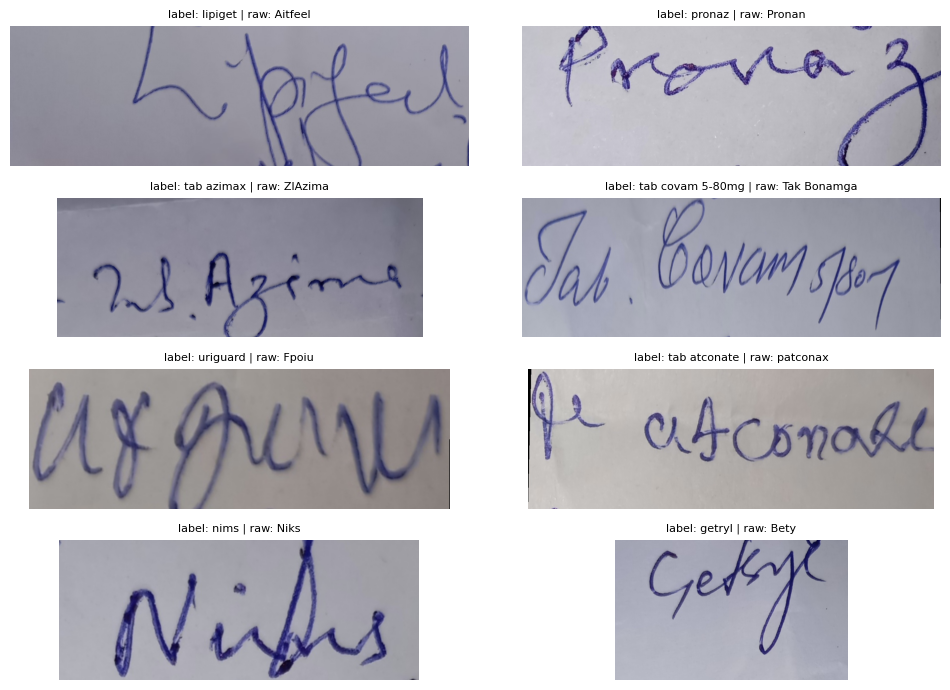

In [6]:
# Preprocessing comaprison / Cell 41
import cv2, re

def make_prep(mode):
    def _prep(path, H=64, W=600):
        a = np.asarray(Image.open(path).convert("RGB"))
        if mode == "gray":
            g = cv2.cvtColor(a, cv2.COLOR_RGB2GRAY)
        elif mode == "clahe":
            g = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(4, 4)).apply(cv2.cvtColor(a, cv2.COLOR_RGB2GRAY))
        elif mode == "ink":            # blue/violet ink has B > R; grey or black print has B ~ R
            d = np.clip(a[..., 2].astype(np.int16) - a[..., 0].astype(np.int16), 0, 255).astype(np.float32)
            d = np.clip(d * 255.0 / max(np.percentile(d, 99.5), 1.0), 0, 255).astype(np.uint8)
            g = 255 - d
        im = Image.fromarray(g)
        w, h = im.size
        nw = min(W, max(1, round(H * w / h)))
        arr = np.asarray(im.resize((nw, H), Image.BICUBIC), dtype=np.float32) / 255.0
        arr = (arr - 0.5) / 0.5
        out = np.repeat(arr[:, -1:], W, axis=1)
        out[:, :nw] = arr
        return torch.from_numpy(out)[None]
    return _prep

prefixes = ["Tab ", "tab ", "Cap ", "cap "]
vocabC = sorted(set(vocabA) | {p + n for n in new_names for p in prefixes})
strip = lambda s: re.sub(r"^(tab|cap) ", "", s, flags=re.I)
L = np.array([len(t) for t in truth])

def score(preds):
    p = [strip(x).lower() for x in preds]
    ed = np.array([edit_distance(a, b) for a, b in zip(p, truth)])
    return round(100 * np.mean(ed == 0), 1), round(100 * np.mean(ed <= 1), 1), round(ed.sum() / L.sum(), 3)

prep_orig = prep                       # `run` looks up the global `prep`, so rebinding it switches the mode
m = load_ft("medical_prescription_aug")
res, saved = [], {}
for mode in ["gray", "clahe", "ink"]:
    prep = make_prep(mode)
    raw, pA = run(m, ft_converter, paths, vocabA)
    _, pC = run(m, ft_converter, paths, vocabC)
    saved[mode] = (raw, pA, pC)
    (rE, r1, rC), (aE, a1, _), (cE, c1, _) = score(raw), score(pA), score(pC)
    res.append({"preprocessing": mode, "raw CER": rC,
                "A exact %": aE, "A within-1 %": a1,
                "A + tab/cap variants exact %": cE, "within-1 %": c1})
prep = prep_orig                       # restore for any other cell
del m; gc.collect(); torch.cuda.empty_cache()
print(pd.DataFrame(res).to_string(index=False))

# eyeball: 8 random photos with truth and the raw read (plain grey mode)
import matplotlib.pyplot as plt
raw_g = saved["gray"][0]
pick = np.random.default_rng(0).choice(len(paths), 8, replace=False)
fig, axes = plt.subplots(4, 2, figsize=(10, 7))
for ax, i in zip(axes.ravel(), pick):
    ax.imshow(Image.open(paths[i])); ax.axis("off")
    ax.set_title(f'label: {df["label"].iloc[i]} | raw: {raw_g[i]}', fontsize=8)
plt.tight_layout(); plt.show()

In [7]:
# Top-k + length-normalised scoring / Cell 42
import time

@torch.no_grad()
def nll_matrix(model, paths, names, chunk=200):
    chunks = [names[i:i + chunk] for i in range(0, len(names), chunk)]
    enc = [ft_converter.encode(c) for c in chunks]
    M = np.zeros((len(paths), len(names)), dtype=np.float32)
    for i in range(0, len(paths), 32):
        x = torch.stack([prep(p) for p in paths[i:i + 32]]).to(device)
        out = model(x, torch.zeros(len(x), 1, dtype=torch.long, device=device))
        logp = out.log_softmax(2).float().cpu()
        T, C = logp.size(1), logp.size(2)
        for b in range(len(x)):
            col = 0
            for c_names, (v_text, v_len) in zip(chunks, enc):
                Vc = len(c_names)
                lp = logp[b][:, None, :].expand(T, Vc, C).contiguous()
                nll = F.ctc_loss(lp, v_text, torch.full((Vc,), T, dtype=torch.int32), v_len,
                                 blank=0, reduction="none", zero_infinity=True)
                M[i + b, col:col + Vc] = nll.numpy(); col += Vc
    return M

# vocab B plus the tab/cap variants of the Kaggle names (the 704 names + variants)
vocab_list = sorted(set(vocabB) | set(vocabC))
names = np.array(vocab_list, dtype=object)
lens = np.array([len(n) for n in vocab_list], dtype=np.float32)

prep = make_prep("gray")
m = load_ft("medical_prescription_aug")
M = nll_matrix(m, paths, vocab_list)
del m; gc.collect(); torch.cuda.empty_cache()
np.save(WORK / "kaggle_nll.npy", M)

def topk_report(S, label):
    rank = np.argsort(S, axis=1)
    out = {"scoring": label}
    for k in (1, 3, 5):
        hit = [t in {strip(n).lower() for n in names[r[:k]]} for r, t in zip(rank, truth)]
        out[f"top-{k} %"] = round(100 * np.mean(hit), 1)
    return out

rows = [topk_report(M, "raw NLL"),
        topk_report(M / lens[None, :], "NLL / length")]
print(pd.DataFrame(rows).to_string(index=False))

No Transformation module specified
     scoring  top-1 %  top-3 %  top-5 %
     raw NLL     44.8     58.6     64.4
NLL / length     49.4     63.2     72.4


In [11]:
# Grouped 5-fold split of the Kaggle data / Cell 43
import shutil

df = df.reset_index(drop=True)
MERGE = {"distalgasic": "distalgesic", "toniflex": "tonoflex", "tonoflox": "tonoflex",
         "breeky": "breaky", "cefeget": "cefiget", "novidat": "novidate",
         "movelate": "movalate", "my-d": "my"}
# add azitma->azimax, fixit->fexet, movax->movalate here if the images agree
df["group"] = df["name"].str.split().str[0].replace(MERGE)
print(sorted(df["group"].unique()))

df["train_label"] = df["label"].str.strip().map(title)   # full label, prefix and dose kept
df["png"] = [f"k{i:03d}.png" for i in range(len(df))]

K = 5
fold_of, load = {}, [0] * K
for g, n in df["group"].value_counts().items():          # largest groups first, greedy balance
    f = int(np.argmin(load)); fold_of[g] = f; load[f] += n
df["fold"] = df["group"].map(fold_of)
print(df.groupby("fold").agg(images=("png", "size"), names=("group", "nunique")))

for k in range(K):
    test_f, val_f = k, (k + 1) % K
    parts = {"train": df[~df["fold"].isin([test_f, val_f])],
             "val":   df[df["fold"] == val_f],
             "test":  df[df["fold"] == test_f]}
    for split, d in parts.items():
        out = TRAINER / "all_data" / f"kaggle_f{k}_{split}"
        if out.exists():
            shutil.rmtree(out)
        out.mkdir(parents=True)
        for src, dst in zip(d["path"], d["png"]):
            Image.open(src).convert("RGB").save(out / dst)
        (d[["png", "train_label"]]
           .rename(columns={"png": "filename", "train_label": "words"})
           .to_csv(out / "labels.csv", index=False))
    print(f"fold {k}: train {len(parts['train'])} | val {len(parts['val'])} | test {len(parts['test'])}")

['atcam', 'atcomid', 'atconate', 'azimax', 'azitma', 'bisleri', 'breaky', 'caricef', 'cefiget', 'covam', 'dicloran', 'distalgesic', 'fexet', 'fixit', 'getryl', 'leflox', 'lipiget', 'mesulid', 'montiget', 'movalate', 'movax', 'my', 'na', 'nebil', 'nims', 'novidate', 'ostium', 'pronaz', 'provas', 'risek', 'starcox', 'tonoflex', 'uriguard']
      images  names
fold               
0         18      7
1         18      7
2         17      6
3         17      6
4         17      7
fold 0: train 51 | val 18 | test 18
fold 1: train 52 | val 17 | test 18
fold 2: train 53 | val 17 | test 17
fold 3: train 53 | val 17 | test 17
fold 4: train 52 | val 18 | test 17


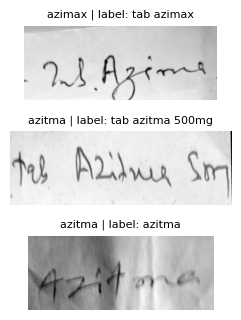

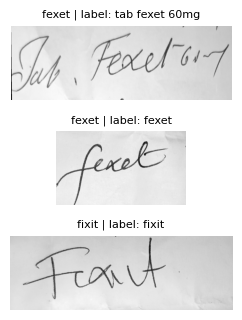

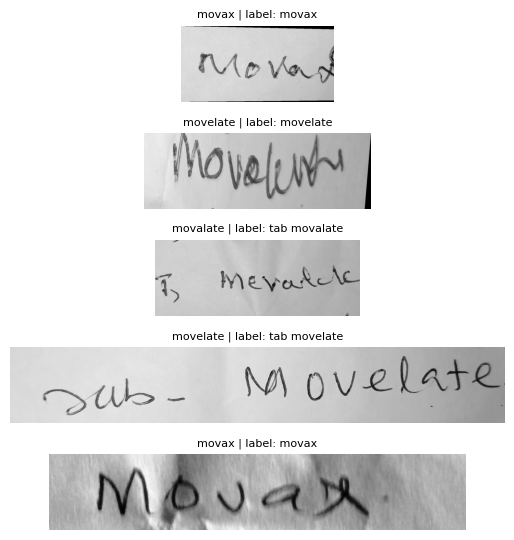

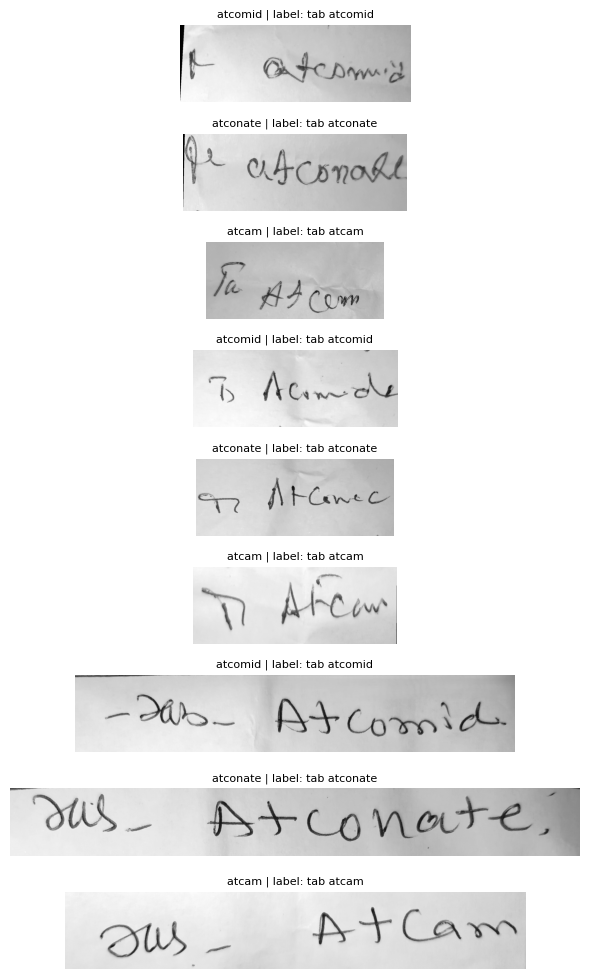

In [10]:
# Eyeball uncertain groups / Cell 43b
import matplotlib.pyplot as plt
for gs in [("azimax", "azitma"), ("fexet", "fixit"), ("movax", "movalate", "movelate"),
           ("atcam", "atcomid", "atconate")]:
    sub = df[df["group"].isin(gs)]
    fig, axes = plt.subplots(len(sub), 1, figsize=(6, 1.1 * len(sub)))
    for ax, (_, r) in zip(np.atleast_1d(axes), sub.iterrows()):
        ax.imshow(Image.open(r["path"]).convert("L"), cmap="gray"); ax.axis("off")
        ax.set_title(f'{r["group"]} | label: {r["label"]}', fontsize=8)
    plt.tight_layout(); plt.show()

In [9]:
# Build app vocab / Cell 44
allowed = set(opt.character)
app_names = sorted({n for n in (set(train_names) | set(new_names) | set(gen))
                    if 2 <= len(n) <= 30 and set(n) <= allowed})
APP_VOCAB = Path(r"D:\Projects\MediLens\app\vocab.txt")
APP_VOCAB.write_text("\n".join(app_names), encoding="utf-8")
print(len(app_names), "names written to", APP_VOCAB)

for probe in ["Atcomid", "Atconate", "Tonoflex", "Azimax", "Azitona", "Tonoflox"]:
    print(probe, "->", "in vocab" if probe in app_names else "NOT in vocab")

704 names written to D:\Projects\MediLens\app\vocab.txt
Atcomid -> in vocab
Atconate -> in vocab
Tonoflex -> NOT in vocab
Azimax -> in vocab
Azitona -> NOT in vocab
Tonoflox -> in vocab


In [ ]:
# Out-of-fold evaluation vs no fine-tuning / Cell 45
prep = make_prep("gray")
Mk = np.zeros_like(M)
for k in range(5):
    rows = np.where(df["fold"].values == k)[0]
    m = load_ft(f"kaggle_e400_f{k}")
    Mk[rows] = nll_matrix(m, [paths[i] for i in rows], vocab_list)
    del m; gc.collect(); torch.cuda.empty_cache()
np.save(WORK / "kaggle_e400_oof_nll.npy", Mk)

def gkey(n):                       # vocab entry -> drug key, same rule as df["group"]
    t = strip(n).lower().split()[0]
    return MERGE.get(t, t)
vg = [gkey(n) for n in names]

def topk_hits(S, ks=(1, 3, 5)):    # dedupes Tab/Cap variants so they don't eat slots
    truth_g = df["group"].values
    out = {k: np.zeros(len(df), bool) for k in ks}
    for i in range(len(df)):
        seen = []
        for j in np.argsort(S[i]):
            if vg[j] not in seen:
                seen.append(vg[j])
            if len(seen) == max(ks):
                break
        for k in ks:
            out[k][i] = truth_g[i] in seen[:k]
    return out

base_h = topk_hits(M / lens[None, :])      # no fine-tuning (same recipe as Cell 42)
ft_h   = topk_hits(Mk / lens[None, :])     # out-of-fold fine-tuned

# cluster bootstrap over drugs (images of one drug are not independent)
rng = np.random.default_rng(0)
G = [np.where(df["group"].values == g)[0] for g in df["group"].unique()]
boots = [np.concatenate([G[j] for j in rng.integers(0, len(G), len(G))]) for _ in range(2000)]
tab = []
for k in (1, 3, 5):
    b, f = base_h[k], ft_h[k]
    d = np.array([f[ix].mean() - b[ix].mean() for ix in boots]) * 100
    tab.append({"top-k": k, "no fine-tune %": round(b.mean() * 100, 1),
                "fold fine-tune %": round(f.mean() * 100, 1),
                "gain (pts)": round((f.mean() - b.mean()) * 100, 1),
                "95% CI of gain": f"[{np.percentile(d, 2.5):.1f}, {np.percentile(d, 97.5):.1f}]"})
print(pd.DataFrame(tab).to_string(index=False))
print(df.assign(hit=ft_h[1]).groupby("fold")["hit"].mean().round(3))

No Transformation module specified
No Transformation module specified
No Transformation module specified
No Transformation module specified
No Transformation module specified
 top-k  no fine-tune %  fold fine-tune %  gain (pts) 95% CI of gain
     1            51.7              59.8         8.0   [-1.2, 16.7]
     3            66.7              73.6         6.9   [-2.3, 15.1]
     5            73.6              77.0         3.4   [-5.3, 11.1]
fold
0    0.500
1    0.667
2    0.529
3    0.588
4    0.706
Name: hit, dtype: float64


In [ ]:
# Fixed vs broken images and per-fold rates / Cell 46
for k_ in (1, 3):
    b, f = base_h[k_], ft_h[k_]
    print(f"top-{k_}: fixed {int((~b & f).sum())} | broken {int((b & ~f).sum())}")
print(pd.DataFrame({"fold": df["fold"], "base top-1": base_h[1], "ft top-1": ft_h[1],
                    "base top-3": base_h[3], "ft top-3": ft_h[3]})
        .groupby("fold").mean().mul(100).round(1))